# AL07176302 - Kevin Flores Caloch
## ACTIVIDAD 5

In [5]:
%pip install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<2" "scipy>=1.13,<2" "matplotlib>=3.8,<4" "mlflow>=3,<4" "joblib>=1.4,<2" "nbformat>=5.10,<6"

Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import pandas as pd
import sklearn
import scipy
import matplotlib
import mlflow
import joblib
import nbformat

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)
print("\nImportaciones completadas correctamente.")

NumPy: 1.26.4
Pandas: 2.2.2
Scikit-learn: 1.8.0
MLflow: 3.17.1

Importaciones completadas correctamente.


In [7]:
from pathlib import Path

ubicacion = Path.cwd().resolve()
if ubicacion.name == "fuentes":
    BASE = ubicacion.parent
elif ubicacion.name == "Actividad_5":
    BASE = ubicacion
else:
    BASE = ubicacion / "Actividad_5"

carpetas = [
    "datos/datos_ini",
    "datos/datos_limp",
    "fuentes",
    "evidencias",
    "resultados",
    "modelos",
]

for carpeta in carpetas:
    (BASE / carpeta).mkdir(parents=True, exist_ok=True)

print("Carpeta del proyecto:", BASE.resolve())
print("\nCarpetas disponibles:")
for carpeta in carpetas:
    print(f"  ✓ {carpeta}")

Carpeta del proyecto: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5

Carpetas disponibles:
  ✓ datos/datos_ini
  ✓ datos/datos_limp
  ✓ fuentes
  ✓ evidencias
  ✓ resultados
  ✓ modelos


In [8]:
from sklearn.datasets import load_iris

# Carga el dataset incluido en scikit-learn.
iris = load_iris(as_frame=True)
datos_originales = iris.frame.copy()

# Guarda los datos originales.
ruta_original = BASE / "datos" / "datos_ini" / "iris_original.csv"
datos_originales.to_csv(ruta_original, index=False)

# Guarda la descripción y la correspondencia de clases.
(BASE / "datos" / "datos_ini" / "descripcion_iris.txt").write_text(
    iris.DESCR,
    encoding="utf-8"
)

clases = dict(enumerate(iris.target_names))
print("Archivo guardado en:", ruta_original)
print("Dimensiones:", datos_originales.shape)
print("Clases:", clases)

display(datos_originales.head())

Archivo guardado en: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\datos\datos_ini\iris_original.csv
Dimensiones: (150, 5)
Clases: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [13]:
import json

datos_limpios = datos_originales.copy()

# Estandarizar los nombres de las columnas.
datos_limpios = datos_limpios.rename(columns={
    "sepal length (cm)": "largo_sepalo_cm",
    "sepal width (cm)": "ancho_sepalo_cm",
    "petal length (cm)": "largo_petalo_cm",
    "petal width (cm)": "ancho_petalo_cm",
})

variables = [
    "largo_sepalo_cm",
    "ancho_sepalo_cm",
    "largo_petalo_cm",
    "ancho_petalo_cm",
]

# Asegurar tipos numéricos.
for columna in variables + ["target"]:
    datos_limpios[columna] = pd.to_numeric(
        datos_limpios[columna], errors="raise"
    )

nulos = int(datos_limpios.isna().sum().sum())
duplicados = int(datos_limpios.duplicated().sum())

# Validar medidas positivas y clases permitidas.
assert datos_limpios[variables].gt(0).all().all(), \
    "Se encontraron medidas nulas o negativas."
assert datos_limpios["target"].isin([0, 1, 2]).all(), \
    "Se encontraron clases inválidas."

# Quitar filas completamente idénticas antes de dividir los datos.
datos_limpios = datos_limpios.drop_duplicates().reset_index(drop=True)
datos_limpios["target"] = datos_limpios["target"].astype("int64")

# Guardar versión limpia.
ruta_limpia = BASE / "datos" / "datos_limp" / "iris_limpio_v1.csv"
datos_limpios.to_csv(ruta_limpia, index=False)

resumen_limpieza = { # Documentar actividad
    "version": "v1",
    "filas_originales": len(datos_originales),
    "filas_limpias": len(datos_limpios),
    "valores_nulos": nulos,
    "duplicados_eliminados": duplicados,
    "criterio_duplicados": (
        "Eliminar filas idénticas en características y objetivo para "
        "evitar que copias exactas aparezcan en entrenamiento y prueba. "
        "Sin identificadores, no puede verificarse si eran flores distintas."
    ),
    "tratamiento_nulos": (
        "Si existen nulos en las características, se imputarán dentro "
        "del pipeline de entrenamiento."
    ),
    "escalado": "Se ajustará únicamente con datos de entrenamiento.",
    "categoricas": (
        "No hay características categóricas; target ya está codificado."
    ),
}

(BASE / "resultados" / "resumen_limpieza.json").write_text(
    json.dumps(resumen_limpieza, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Valores nulos:", nulos)
print("Duplicados eliminados:", duplicados)
print("Dimensiones finales:", datos_limpios.shape)
print("Archivo guardado en:", ruta_limpia)

display(datos_limpios.head())

Valores nulos: 0
Duplicados eliminados: 1
Dimensiones finales: (149, 5)
Archivo guardado en: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\datos\datos_limp\iris_limpio_v1.csv


,largo_sepalo_cm,ancho_sepalo_cm,largo_petalo_cm,ancho_petalo_cm,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


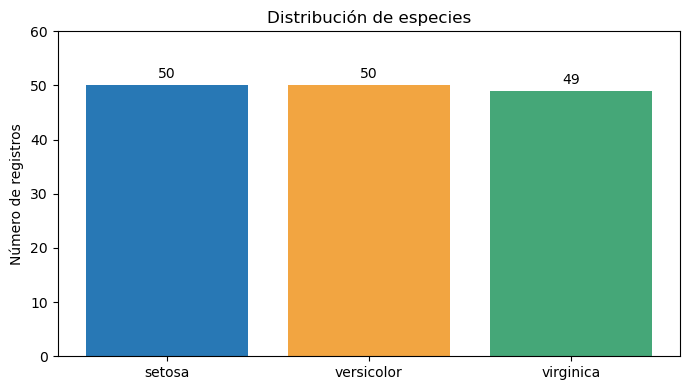

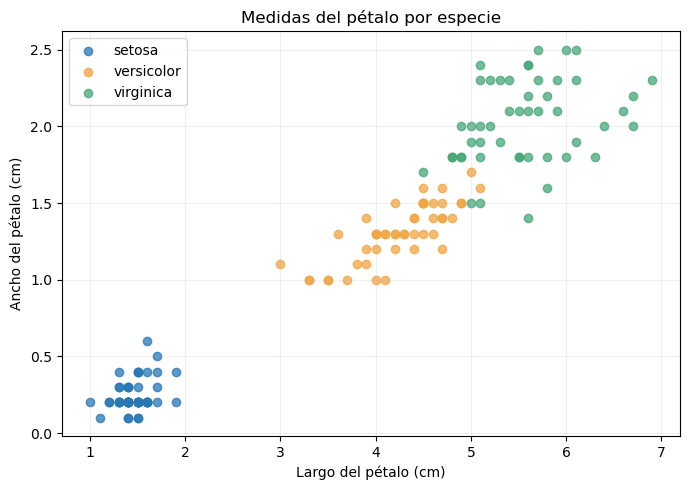

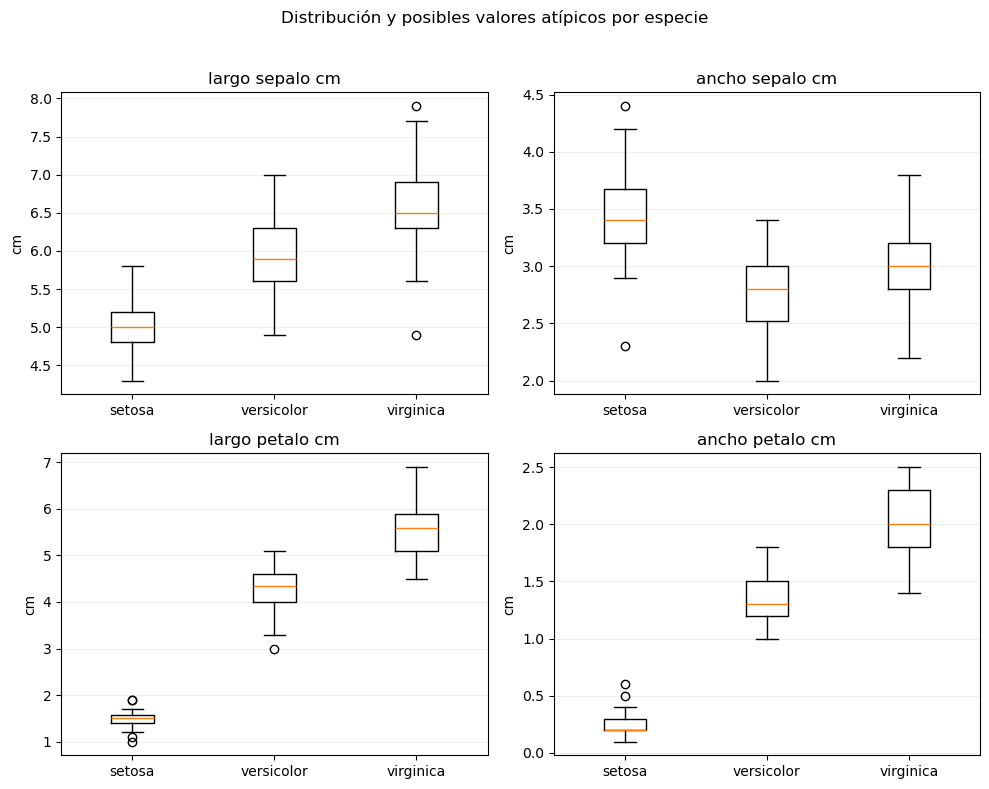

,especie,variable,posibles_atipicos
0,setosa,largo_sepalo_cm,0
1,setosa,ancho_sepalo_cm,2
2,setosa,largo_petalo_cm,4
3,setosa,ancho_petalo_cm,2
4,versicolor,largo_sepalo_cm,0
5,versicolor,ancho_sepalo_cm,0
6,versicolor,largo_petalo_cm,1
7,versicolor,ancho_petalo_cm,0
8,virginica,largo_sepalo_cm,2
9,virginica,ancho_sepalo_cm,0


Gráficas y tabla guardadas en: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\resultados


In [14]:
import matplotlib.pyplot as plt

nombres_clases = {
    0: "setosa",
    1: "versicolor",
    2: "virginica",
}

colores = ["#2878B5", "#F2A541", "#45A778"]

# Distribución de clases.
conteos = datos_limpios["target"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    [nombres_clases[c] for c in conteos.index],
    conteos.values,
    color=colores,
)

ax.bar_label(barras, padding=3)
ax.set(title="Distribución de especies", ylabel="Número de registros")
ax.set_ylim(0, conteos.max() + 10)

fig.tight_layout()
fig.savefig(BASE / "resultados" / "distribucion_clases.png", dpi=180)
plt.show()


# Relación entre largo y ancho del pétalo.
fig, ax = plt.subplots(figsize=(7, 5))

for clase, color in zip(nombres_clases, colores):
    grupo = datos_limpios[datos_limpios["target"] == clase]

    ax.scatter(
        grupo["largo_petalo_cm"],
        grupo["ancho_petalo_cm"],
        label=nombres_clases[clase],
        color=color,
        alpha=0.75,
    )

ax.set(
    title="Medidas del pétalo por especie",
    xlabel="Largo del pétalo (cm)",
    ylabel="Ancho del pétalo (cm)",
)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(BASE / "resultados" / "dispersion_petalos.png", dpi=180)
plt.show()


# Diagramas de caja por especie.
fig, ejes = plt.subplots(2, 2, figsize=(10, 8))

for ax, variable in zip(ejes.flat, variables):
    grupos = [
        datos_limpios.loc[datos_limpios["target"] == clase, variable]
        for clase in nombres_clases
    ]

    ax.boxplot(grupos)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(list(nombres_clases.values()))
    ax.set_title(variable.replace("_", " "))
    ax.set_ylabel("cm")
    ax.grid(axis="y", alpha=0.2)

fig.suptitle("Distribución y posibles valores atípicos por especie")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(BASE / "resultados" / "boxplots_por_especie.png", dpi=180)
plt.show()


# Detectar posibles atípicos con la regla de 1.5 × IQR por especie.
resumen_atipicos = []

for clase, especie in nombres_clases.items():
    grupo = datos_limpios[datos_limpios["target"] == clase]

    for variable in variables:
        q1 = grupo[variable].quantile(0.25)
        q3 = grupo[variable].quantile(0.75)
        iqr = q3 - q1

        mascara = (
            (grupo[variable] < q1 - 1.5 * iqr)
            | (grupo[variable] > q3 + 1.5 * iqr)
        )

        resumen_atipicos.append({
            "especie": especie,
            "variable": variable,
            "posibles_atipicos": int(mascara.sum()),
        })

tabla_atipicos = pd.DataFrame(resumen_atipicos)
tabla_atipicos.to_csv(
    BASE / "resultados" / "posibles_atipicos.csv",
    index=False,
)

display(tabla_atipicos)
print("Gráficas y tabla guardadas en:", BASE / "resultados")

In [15]:
from sklearn.model_selection import train_test_split
import hashlib

SEMILLA = 42

X = datos_limpios[variables].copy()
y = datos_limpios["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y,
)

# Guardar las particiones sin escalar.
entrenamiento = X_train.join(y_train)
prueba = X_test.join(y_test)

entrenamiento.to_csv(
    BASE / "datos" / "datos_limp" / "entrenamiento_v1.csv",
    index_label="fila_id",
)

prueba.to_csv(
    BASE / "datos" / "datos_limp" / "prueba_v1.csv",
    index_label="fila_id",
)

# Registrar versión, huellas digitales y división de los datos.
archivos_datos = [
    BASE / "datos" / "datos_ini" / "iris_original.csv",
    BASE / "datos" / "datos_limp" / "iris_limpio_v1.csv",
    BASE / "datos" / "datos_limp" / "entrenamiento_v1.csv",
    BASE / "datos" / "datos_limp" / "prueba_v1.csv",
]

version_datos = {
    "version": "v1",
    "semilla": SEMILLA,
    "proporcion_prueba": 0.20,
    "division": "estratificada por especie",
    "filas_entrenamiento": len(X_train),
    "filas_prueba": len(X_test),
    "sha256": {
        str(ruta.relative_to(BASE)): hashlib.sha256(
            ruta.read_bytes()
        ).hexdigest()
        for ruta in archivos_datos
    },
}

(BASE / "datos" / "version_datos_v1.json").write_text(
    json.dumps(version_datos, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

distribucion = pd.DataFrame({
    "entrenamiento": y_train.value_counts(),
    "prueba": y_test.value_counts(),
}).sort_index()

distribucion.index = [
    nombres_clases[clase] for clase in distribucion.index
]
distribucion.index.name = "especie"

display(distribucion)

print("Particiones y registro de versión guardados.")

Registros de entrenamiento: 119
Registros de prueba: 30


,entrenamiento,prueba
especie,,
setosa,40,10
versicolor,40,10
virginica,39,10


Particiones y registro de versión guardados.


In [16]:
import mlflow
from mlflow.tracking import MlflowClient

# Base de datos local para el historial de experimentos.
ruta_db = (BASE / "mlflow.db").resolve()
TRACKING_URI = "sqlite:///" + ruta_db.as_posix()

mlflow.set_tracking_uri(TRACKING_URI)

# Carpeta para los artefactos: modelos, tablas y gráficas.
ruta_artefactos = (BASE / "mlartifacts").resolve()
ruta_artefactos.mkdir(parents=True, exist_ok=True)

NOMBRE_EXPERIMENTO = "Actividad5_Iris"

cliente = MlflowClient()
experimento = cliente.get_experiment_by_name(NOMBRE_EXPERIMENTO)

if experimento is None:
    cliente.create_experiment(
        name=NOMBRE_EXPERIMENTO,
        artifact_location=ruta_artefactos.as_uri(),
    )

mlflow.set_experiment(NOMBRE_EXPERIMENTO)

# Registro de comprobación, no es entrenamiento todavía
with mlflow.start_run(run_name="verificacion_configuracion") as run:
    mlflow.set_tag("tipo", "verificacion")
    mlflow.log_param("dataset", "Iris")
    mlflow.log_param("version_datos", "v1")
    mlflow.log_param("semilla", SEMILLA)

    mlflow.log_metric("filas_entrenamiento", len(X_train))
    mlflow.log_metric("filas_prueba", len(X_test))

    mlflow.log_artifact(
        str(BASE / "datos" / "version_datos_v1.json"),
        artifact_path="datos",
    )

    run_id_verificacion = run.info.run_id

# Confirmación del registro
registro = cliente.get_run(run_id_verificacion)
artefactos = cliente.list_artifacts(run_id_verificacion, "datos")

assert registro.info.status == "FINISHED"
assert registro.data.params["dataset"] == "Iris"
assert registro.data.metrics["filas_entrenamiento"] == len(X_train)
assert any(
    archivo.path == "datos/version_datos_v1.json"
    for archivo in artefactos
)

print("MLflow configurado correctamente.")
print("Experimento:", NOMBRE_EXPERIMENTO)
print("Run ID:", run_id_verificacion)
print("Base de datos:", ruta_db)
print("Parámetros, métricas y artefacto verificados.")

2026/10/20 22:36:50 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/20 22:36:50 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

MLflow configurado correctamente.
Experimento: Actividad5_Iris
Run ID: 515de39fc3494c4c8cfb6fc1107e248a
Base de datos: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\mlflow.db
Parámetros, métricas y artefacto verificados.


In [17]:
import json
import time
import joblib
import pandas as pd
import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from mlflow.models import infer_signature

version_datos["sha256"] = {
    ruta.replace("\\", "/"): huella
    for ruta, huella in version_datos["sha256"].items()
}

(BASE / "datos" / "version_datos_v1.json").write_text(
    json.dumps(version_datos, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

huella_datos = version_datos["sha256"][
    "datos/datos_limp/iris_limpio_v1.csv"
]

# Recuperar la configuración local de MLflow.
ruta_db = (BASE / "mlflow.db").resolve()
TRACKING_URI = "sqlite:///" + ruta_db.as_posix()

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment("Actividad5_Iris")


# Validación cruzada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA,
)

# Ambos algoritmos usarán exactamente las mismas particiones.
particiones_cv = list(cv.split(X_train, y_train))


# Modelos e hiperparápametros
configuraciones = {
    "regresion_logistica": {
        "pipeline": Pipeline([
            (
                "imputacion",
                SimpleImputer(strategy="median"),
            ),
            (
                "escalado",
                StandardScaler(),
            ),
            (
                "modelo",
                LogisticRegression(
                    max_iter=2000,
                    solver="lbfgs",
                    random_state=SEMILLA,
                ),
            ),
        ]),
        "parametros": {
            "modelo__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        },
    },

    "random_forest": {
        "pipeline": Pipeline([
            (
                "imputacion",
                SimpleImputer(strategy="median"),
            ),
            (
                "modelo",
                RandomForestClassifier(
                    random_state=SEMILLA,
                    n_jobs=1,
                ),
            ),
        ]),
        "parametros": {
            "modelo__n_estimators": [100, 200],
            "modelo__max_depth": [None, 3, 5],
            "modelo__min_samples_leaf": [1, 2],
        },
    },
}


# Entrenamiento y registro en MLflow

busquedas = {}
modelos_entrenados = {}
runs_modelos = {}
resumen_cv = []

metricas = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "roc_auc_ovr_macro",
]

for nombre, configuracion in configuraciones.items():

    print(f"\nEntrenando: {nombre}")

    with mlflow.start_run(run_name=nombre) as run:

        inicio = time.perf_counter()

        busqueda = GridSearchCV(
            estimator=configuracion["pipeline"],
            param_grid=configuracion["parametros"],
            scoring={
                "accuracy": "accuracy",
                "precision_macro": "precision_macro",
                "recall_macro": "recall_macro",
                "f1_macro": "f1_macro",
                "roc_auc_ovr_macro": "roc_auc_ovr",
            },
            refit="f1_macro",
            cv=particiones_cv,
            n_jobs=-1,
            return_train_score=True,
            error_score="raise",
        )

        # Solo se utilizan los datos de entrenamiento.
        busqueda.fit(X_train, y_train)

        segundos = time.perf_counter() - inicio
        mejor_modelo = busqueda.best_estimator_
        indice_mejor = busqueda.best_index_

        # Guardar resultados de todas las combinaciones.
        tabla_cv = pd.DataFrame(busqueda.cv_results_)

        ruta_cv = (
            BASE / "resultados" / f"gridsearch_{nombre}.csv"
        )

        tabla_cv.to_csv(ruta_cv, index=False)

        # Guardar una copia local del pipeline entrenado.
        ruta_modelo = (
            BASE / "modelos" / f"{nombre}.joblib"
        )

        joblib.dump(mejor_modelo, ruta_modelo)

        # Etiquetas de trazabilidad.
        mlflow.set_tags({
            "tipo": "entrenamiento",
            "dataset": "Iris",
            "version_datos": "v1",
            "criterio_seleccion": "f1_macro_cv",
        })

        # Parámetros generales y mejores hiperparámetros.
        mlflow.log_params({
            "algoritmo": nombre,
            "semilla": SEMILLA,
            "cv_particiones": 5,
            "filas_entrenamiento": len(X_train),
            "numero_combinaciones": len(tabla_cv),
            "datos_sha256": huella_datos,
            "serializacion": "cloudpickle",
        })

        mlflow.log_params(busqueda.best_params_)

        mlflow.log_dict(
            configuracion["parametros"],
            "configuracion/rejilla.json",
        )

        # Guardar las particiones utilizadas en la validación.
        mlflow.log_dict(
            {
                "particiones": [
                    {
                        "fold": numero,
                        "indices_entrenamiento": indices_train.tolist(),
                        "indices_validacion": indices_val.tolist(),
                    }
                    for numero, (indices_train, indices_val)
                    in enumerate(particiones_cv, start=1)
                ],
                "nota": (
                    "Índices posicionales relativos al orden de X_train."
                ),
            },
            "configuracion/particiones_cv.json",
        )

        # Métricas de la mejor combinación.
        metricas_cv = {
            "busqueda_segundos": segundos,
        }

        for metrica in metricas:
            metricas_cv[f"cv_{metrica}_media"] = float(
                busqueda.cv_results_[
                    f"mean_test_{metrica}"
                ][indice_mejor]
            )

            metricas_cv[f"cv_{metrica}_std"] = float(
                busqueda.cv_results_[
                    f"std_test_{metrica}"
                ][indice_mejor]
            )

        mlflow.log_metrics(metricas_cv)

        # Registrar tablas y versión de datos.
        mlflow.log_artifact(
            str(ruta_cv),
            artifact_path="validacion",
        )

        mlflow.log_artifact(
            str(BASE / "datos" / "version_datos_v1.json"),
            artifact_path="datos",
        )

        # Definir entradas y salidas del modelo.
        firma = infer_signature(
            X_train,
            mejor_modelo.predict(X_train),
        )

        # Indicar cloudpickle explícitamente para evitar el error de tipos de skops.
        mlflow.sklearn.log_model(
            sk_model=mejor_modelo,
            name="modelo",
            signature=firma,
            input_example=X_train.head(3),
            serialization_format="cloudpickle",
        )

        # Conservar objetos para la evaluación posterior.
        busquedas[nombre] = busqueda
        modelos_entrenados[nombre] = mejor_modelo
        runs_modelos[nombre] = run.info.run_id

        resumen_cv.append({
            "modelo": nombre,
            "f1_macro_cv": metricas_cv["cv_f1_macro_media"],
            "std_f1_cv": metricas_cv["cv_f1_macro_std"],
            "accuracy_cv": metricas_cv["cv_accuracy_media"],
            "roc_auc_cv": metricas_cv[
                "cv_roc_auc_ovr_macro_media"
            ],
            "tiempo_busqueda_s": segundos,
            "mejores_parametros": json.dumps(
                busqueda.best_params_
            ),
            "run_id": run.info.run_id,
        })

        print("Mejores parámetros:", busqueda.best_params_)
        print(f"F1 macro CV: {busqueda.best_score_:.4f}")
        print(f"Tiempo de búsqueda: {segundos:.2f} segundos")
        print("Modelo guardado en MLflow.")


# Comparación y selección
# Si hay empate exacto en F1, se prefiere regresión logística por su menor complejidad.
comparacion_cv = pd.DataFrame(resumen_cv)

comparacion_cv["orden_desempate"] = (
    comparacion_cv["modelo"].map({
        "regresion_logistica": 0,
        "random_forest": 1,
    })
)

comparacion_cv = (
    comparacion_cv
    .sort_values(
        ["f1_macro_cv", "orden_desempate"],
        ascending=[False, True],
    )
    .drop(columns="orden_desempate")
    .reset_index(drop=True)
)

comparacion_cv.to_csv(
    BASE / "resultados" / "comparacion_validacion_cruzada.csv",
    index=False,
)

(BASE / "resultados" / "runs_modelos.json").write_text(
    json.dumps(runs_modelos, indent=2),
    encoding="utf-8",
)

modelo_seleccionado = comparacion_cv.iloc[0]["modelo"]

display(comparacion_cv)

print(
    "\nModelo seleccionado por validación cruzada:",
    modelo_seleccionado,
)
print("Entrenamiento y registro en MLflow completados.")
print("Los datos de prueba todavía no se han utilizado.")


Entrenando: regresion_logistica


2026/10/20 22:39:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mejores parámetros: {'modelo__C': 1.0}
F1 macro CV: 0.9629
Tiempo de búsqueda: 10.62 segundos
Modelo guardado en MLflow.

Entrenando: random_forest


2026/10/20 22:39:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
F1 macro CV: 0.9347
Tiempo de búsqueda: 5.85 segundos
Modelo guardado en MLflow.


,modelo,f1_macro_cv,std_f1_cv,accuracy_cv,roc_auc_cv,tiempo_busqueda_s,mejores_parametros,run_id
0,regresion_logistica,0.962926,0.055644,0.965580,0.996548,10.621479,"{""modelo__C"": 1.0}",fea23ac0261a417ab28b4c7d5ad3da0b
1,random_forest,0.934703,0.074294,0.940217,0.997178,5.849770,"{""modelo__max_depth"": null, ""modelo__min_sampl...",e9515a59aa4d431cbe58355aa3cce153



Modelo seleccionado por validación cruzada: regresion_logistica
Entrenamiento y registro en MLflow completados.
Los datos de prueba todavía no se han utilizado.


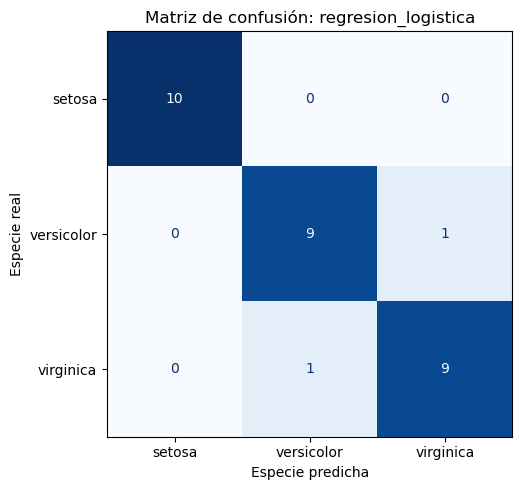

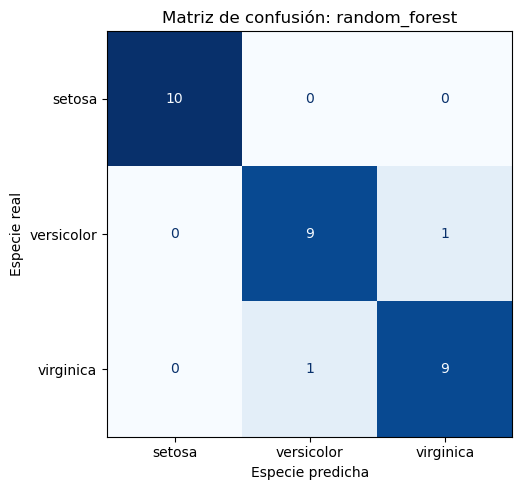

,modelo,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc_ovr_macro
0,regresion_logistica,0.9333,0.9333,0.9333,0.9333,0.9967
1,random_forest,0.9333,0.9333,0.9333,0.9333,0.9867


Modelo seleccionado previamente por CV: regresion_logistica
Evaluación de prueba registrada en MLflow.


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)

resultados_prueba = []
predicciones_prueba = {}
probabilidades_prueba = {}

for nombre, modelo in modelos_entrenados.items():

    predicciones = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)

    predicciones_prueba[nombre] = predicciones
    probabilidades_prueba[nombre] = probabilidades

    metricas_prueba = {
        "test_accuracy": accuracy_score(y_test, predicciones),
        "test_precision_macro": precision_score(
            y_test, predicciones,
            average="macro", zero_division=0,
        ),
        "test_recall_macro": recall_score(
            y_test, predicciones,
            average="macro", zero_division=0,
        ),
        "test_f1_macro": f1_score(
            y_test, predicciones,
            average="macro", zero_division=0,
        ),
        "test_roc_auc_ovr_macro": roc_auc_score(
            y_test,
            probabilidades,
            labels=modelo.classes_,
            multi_class="ovr",
            average="macro",
        ),
    }

    # Reporte de desempeño por especie.
    reporte = classification_report(
        y_test,
        predicciones,
        labels=modelo.classes_,
        target_names=[
            nombres_clases[int(clase)]
            for clase in modelo.classes_
        ],
        output_dict=True,
        zero_division=0,
    )

    ruta_reporte = (
        BASE / "resultados" / f"reporte_clasificacion_{nombre}.csv"
    )
    pd.DataFrame(reporte).transpose().to_csv(ruta_reporte)

    # Guardar predicciones y probabilidades por registro.
    detalle = X_test.copy()
    detalle["target_real"] = y_test
    detalle["target_predicho"] = predicciones

    for posicion, clase in enumerate(modelo.classes_):
        detalle[f"probabilidad_{nombres_clases[int(clase)]}"] = (
            probabilidades[:, posicion]
        )

    ruta_predicciones = (
        BASE / "resultados" / f"predicciones_{nombre}.csv"
    )
    detalle.to_csv(ruta_predicciones, index_label="fila_id")

    # Matriz de confusión.
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=modelo.classes_,
        display_labels=[
            nombres_clases[int(clase)]
            for clase in modelo.classes_
        ],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(f"Matriz de confusión: {nombre}")
    ax.set_xlabel("Especie predicha")
    ax.set_ylabel("Especie real")

    fig.tight_layout()

    ruta_matriz = (
        BASE / "resultados" / f"matriz_confusion_{nombre}.png"
    )
    fig.savefig(ruta_matriz, dpi=180)
    plt.show()

    # Añadir la evaluación al mismo run del entrenamiento.
    with mlflow.start_run(run_id=runs_modelos[nombre]):
        mlflow.log_metrics(metricas_prueba)
        mlflow.set_tag(
            "seleccionado_por_cv",
            str(nombre == modelo_seleccionado).lower(),
        )

        for ruta in [
            ruta_reporte,
            ruta_predicciones,
            ruta_matriz,
        ]:
            mlflow.log_artifact(
                str(ruta),
                artifact_path="evaluacion_prueba",
            )

    resultados_prueba.append({
        "modelo": nombre,
        **metricas_prueba,
    })

comparacion_prueba = pd.DataFrame(resultados_prueba)

ruta_comparacion = (
    BASE / "resultados" / "comparacion_prueba.csv"
)
comparacion_prueba.to_csv(ruta_comparacion, index=False)

display(comparacion_prueba.round(4))

print("Modelo seleccionado previamente por CV:", modelo_seleccionado)
print("Evaluación de prueba registrada en MLflow.")

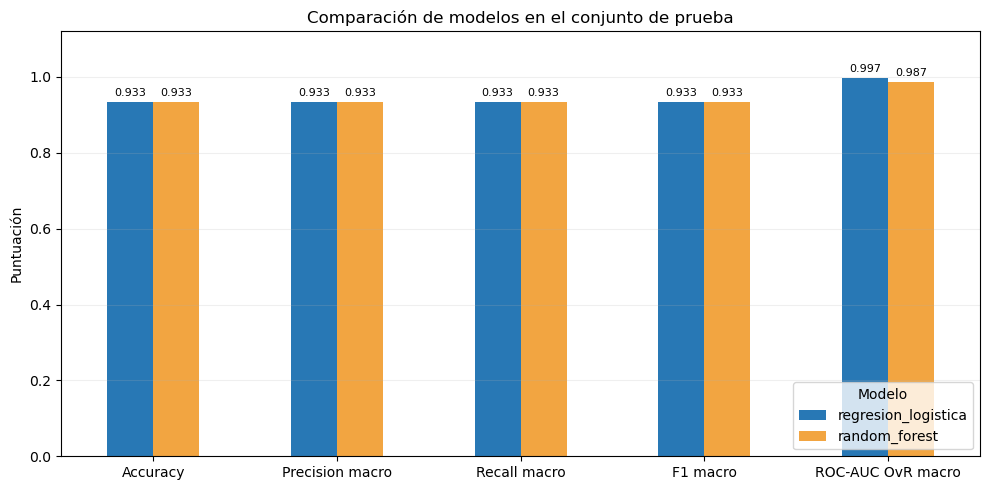

,Random forest acierta,Random forest falla
Logística acierta,28,0
Logística falla,0,2


Pares discordantes: 0
p-valor: 1.0000
Ambos modelos aciertan y fallan en los mismos registros. No hay pares discordantes; se reporta p=1 por convención. Esto no demuestra equivalencia fuera de esta muestra.

Limitación: La muestra de prueba es pequeña. El contraste evalúa tasas de error, no diferencias en F1 ni ROC-AUC.

Comparación guardada y registrada en MLflow.


In [19]:
import numpy as np
from scipy.stats import binomtest

# Comparación pareada sobre los mismos registros de prueba.
reales = np.asarray(y_test)

pred_lr = np.asarray(
    predicciones_prueba["regresion_logistica"]
)
pred_rf = np.asarray(
    predicciones_prueba["random_forest"]
)

acierto_lr = pred_lr == reales
acierto_rf = pred_rf == reales

ambos_aciertan = int(np.sum(acierto_lr & acierto_rf))
solo_lr_acierta = int(np.sum(acierto_lr & ~acierto_rf))
solo_rf_acierta = int(np.sum(~acierto_lr & acierto_rf))
ambos_fallan = int(np.sum(~acierto_lr & ~acierto_rf))

tabla_pareada = pd.DataFrame(
    [
        [ambos_aciertan, solo_lr_acierta],
        [solo_rf_acierta, ambos_fallan],
    ],
    index=["Logística acierta", "Logística falla"],
    columns=["Random forest acierta", "Random forest falla"],
)

discordantes = solo_lr_acierta + solo_rf_acierta

# McNemar exacto: prueba binomial sobre los pares discordantes.
if discordantes > 0:
    p_valor = float(
        binomtest(
            k=solo_lr_acierta,
            n=discordantes,
            p=0.5,
            alternative="two-sided",
        ).pvalue
    )
    interpretacion = (
        "Se detecta una diferencia estadísticamente significativa "
        "en las tasas de error."
        if p_valor < 0.05
        else
        "No se detecta una diferencia estadísticamente significativa "
        "en las tasas de error; esto no demuestra equivalencia."
    )
else:
    # No hay pares discordantes que permitan contrastar diferencias.
    p_valor = 1.0
    interpretacion = (
        "Ambos modelos aciertan y fallan en los mismos registros. "
        "No hay pares discordantes; se reporta p=1 por convención. "
        "Esto no demuestra equivalencia fuera de esta muestra."
    )

analisis_estadistico = {
    "prueba": "McNemar exacto bilateral",
    "muestra": "30 registros de prueba",
    "ambos_aciertan": ambos_aciertan,
    "solo_logistica_acierta": solo_lr_acierta,
    "solo_random_forest_acierta": solo_rf_acierta,
    "ambos_fallan": ambos_fallan,
    "pares_discordantes": discordantes,
    "p_valor": p_valor,
    "nivel_significancia": 0.05,
    "interpretacion": interpretacion,
    "limitacion": (
        "La muestra de prueba es pequeña. El contraste evalúa "
        "tasas de error, no diferencias en F1 ni ROC-AUC."
    ),
}

ruta_estadistica = (
    BASE / "resultados" / "comparacion_estadistica.json"
)
ruta_pareada = BASE / "resultados" / "tabla_mcnemar.csv"

ruta_estadistica.write_text(
    json.dumps(
        analisis_estadistico,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
tabla_pareada.to_csv(ruta_pareada)

# Gráfica comparativa de desempeño en prueba.
columnas_metricas = [
    "test_accuracy",
    "test_precision_macro",
    "test_recall_macro",
    "test_f1_macro",
    "test_roc_auc_ovr_macro",
]

tabla_grafica = (
    comparacion_prueba
    .set_index("modelo")[columnas_metricas]
    .transpose()
)

tabla_grafica.index = [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro",
    "ROC-AUC OvR macro",
]

ax = tabla_grafica.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2878B5", "#F2A541"],
    rot=0,
)

ax.set_title("Comparación de modelos en el conjunto de prueba")
ax.set_ylabel("Puntuación")
ax.set_xlabel("")
ax.set_ylim(0, 1.12)
ax.legend(title="Modelo", loc="lower right")
ax.grid(axis="y", alpha=0.2)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3, fontsize=8)

fig = ax.get_figure()
fig.tight_layout()

ruta_grafica = (
    BASE / "resultados" / "comparacion_modelos_prueba.png"
)
fig.savefig(ruta_grafica, dpi=180)
plt.show()

# Registrar el análisis en ambos runs.
for nombre, run_id in runs_modelos.items():
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metric("mcnemar_p_valor", p_valor)

        for ruta in [
            ruta_estadistica,
            ruta_pareada,
            ruta_grafica,
            ruta_comparacion,
        ]:
            mlflow.log_artifact(
                str(ruta),
                artifact_path="comparacion",
            )

display(tabla_pareada)
print("Pares discordantes:", discordantes)
print(f"p-valor: {p_valor:.4f}")
print(interpretacion)
print("\nLimitación:", analisis_estadistico["limitacion"])
print("\nComparación guardada y registrada en MLflow.")

In [20]:
import subprocess
import sys

# Iniciar MLflow con la misma base de datos del entrenamiento.
ruta_log_mlflow = BASE / "resultados" / "mlflow_panel.log"

with ruta_log_mlflow.open("a", encoding="utf-8") as archivo_log:
    proceso_mlflow = subprocess.Popen(
        [
            sys.executable,
            "-m", "mlflow",
            "ui",
            "--backend-store-uri", TRACKING_URI,
            "--host", "127.0.0.1",
            "--port", "5000",
        ],
        cwd=str(BASE),
        stdout=archivo_log,
        stderr=subprocess.STDOUT,
    )

print("Panel solicitado en: http://127.0.0.1:5000")
print("Si no abre, revisaremos:", ruta_log_mlflow)

Panel solicitado en: http://127.0.0.1:5000
Si no abre, revisaremos: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\resultados\mlflow_panel.log


In [22]:
experimento = mlflow.get_experiment_by_name("Actividad5_Iris")
run_id = runs_modelos["regresion_logistica"]

url = (
    f"http://127.0.0.1:5000/#/experiments/"
    f"{experimento.experiment_id}/runs/{run_id}"
)

print("Enlace para el navegador:")
print(url)

Enlace para el navegador:
http://127.0.0.1:5000/#/experiments/1/runs/fea23ac0261a417ab28b4c7d5ad3da0b


In [24]:
from textwrap import dedent

codigo_preparacion = dedent('''
    """Preparación reproducible del dataset Iris."""

    from pathlib import Path
    import pandas as pd

    SEMILLA = 42

    VARIABLES = [
        "largo_sepalo_cm",
        "ancho_sepalo_cm",
        "largo_petalo_cm",
        "ancho_petalo_cm",
    ]

    NOMBRES_COLUMNAS = {
        "sepal length (cm)": "largo_sepalo_cm",
        "sepal width (cm)": "ancho_sepalo_cm",
        "petal length (cm)": "largo_petalo_cm",
        "petal width (cm)": "ancho_petalo_cm",
    }

    CLASES = {
        0: "setosa",
        1: "versicolor",
        2: "virginica",
    }


    def limpiar_datos(datos):
        """Estandariza nombres y tipos, valida y elimina duplicados.

        Los nulos en características se conservan para imputarlos
        dentro del pipeline. Un objetivo nulo o inválido se rechaza.
        No elimina valores atípicos por criterio estadístico.
        """
        limpios = datos.copy().rename(columns=NOMBRES_COLUMNAS)

        requeridas = VARIABLES + ["target"]
        faltantes = set(requeridas) - set(limpios.columns)

        if faltantes:
            raise ValueError(
                f"Faltan columnas requeridas: {sorted(faltantes)}"
            )

        limpios = limpios[requeridas].copy()

        for columna in requeridas:
            limpios[columna] = pd.to_numeric(
                limpios[columna], errors="raise"
            )

        for columna in VARIABLES:
            valores = limpios[columna].dropna()

            if not (
                valores.gt(0) & valores.lt(float("inf"))
            ).all():
                raise ValueError(
                    f"Medidas no positivas o no finitas en {columna}"
                )

        if not limpios["target"].isin(CLASES).all():
            raise ValueError("Target contiene nulos o clases inválidas.")

        duplicados = int(limpios.duplicated().sum())
        nulos = int(limpios.isna().sum().sum())

        limpios = limpios.drop_duplicates().reset_index(drop=True)
        limpios["target"] = limpios["target"].astype("int64")

        resumen = {
            "version": "v1",
            "filas_originales": len(datos),
            "filas_limpias": len(limpios),
            "valores_nulos": nulos,
            "duplicados_eliminados": duplicados,
            "criterio_duplicados": (
                "Eliminar filas idénticas en características y "
                "objetivo antes de dividir. Sin identificadores "
                "no se puede verificar si eran flores distintas."
            ),
            "tratamiento_nulos": (
                "Imputación de características dentro del pipeline."
            ),
            "escalado": (
                "Se ajusta dentro del pipeline, solo con entrenamiento."
            ),
            "atipicos": "Se conservan; IQR no demuestra error.",
        }

        return limpios, resumen


    def cargar_y_limpiar(ruta_csv):
        """Lee el CSV original y devuelve datos limpios y resumen."""
        originales = pd.read_csv(Path(ruta_csv))
        return limpiar_datos(originales)
''').lstrip()

ruta_script = BASE / "fuentes" / "datos_prep.py"
ruta_script.write_text(codigo_preparacion, encoding="utf-8")

# Cargar el script y comprobar que reproduce la limpieza realizada.
import importlib.util

spec = importlib.util.spec_from_file_location(
    "datos_prep_actividad5", ruta_script
)
modulo_prep = importlib.util.module_from_spec(spec)
spec.loader.exec_module(modulo_prep)

datos_verificados, resumen_verificado = modulo_prep.cargar_y_limpiar(
    BASE / "datos" / "datos_ini" / "iris_original.csv"
)

pd.testing.assert_frame_equal(
    datos_verificados,
    datos_limpios,
)

print("Script creado en:", ruta_script)
print("Verificación correcta: reproduce los 149 registros limpios.")
print("Duplicados eliminados:",
      resumen_verificado["duplicados_eliminados"])

Script creado en: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\fuentes\datos_prep.py
Verificación correcta: reproduce los 149 registros limpios.
Duplicados eliminados: 1


In [30]:
codigo_entrenamiento = r'''
"""Entrenamiento reproducible de Iris y registro local en MLflow.

Ejecutar desde la raíz del proyecto:
    python fuentes/train.py
"""

from pathlib import Path
import hashlib
import json
import platform
import time

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import sklearn

from scipy.stats import binomtest
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from mlflow.models import infer_signature

from datos_prep import cargar_y_limpiar, VARIABLES, CLASES, SEMILLA


BASE = Path(__file__).resolve().parent.parent


def guardar_json(ruta, contenido):
    ruta.write_text(
        json.dumps(contenido, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )


def main():
    for carpeta in [
        "datos/datos_ini",
        "datos/datos_limp",
        "resultados",
        "modelos",
        "mlartifacts",
    ]:
        (BASE / carpeta).mkdir(parents=True, exist_ok=True)

    # Usar el original existente; obtenerlo si falta.
    ruta_original = BASE / "datos/datos_ini/iris_original.csv"

    if not ruta_original.exists():
        iris = load_iris(as_frame=True)
        iris.frame.to_csv(ruta_original, index=False)
        (ruta_original.parent / "descripcion_iris.txt").write_text(
            iris.DESCR, encoding="utf-8"
        )

    datos, resumen = cargar_y_limpiar(ruta_original)

    ruta_limpia = BASE / "datos/datos_limp/iris_limpio_v1.csv"
    datos.to_csv(ruta_limpia, index=False)
    guardar_json(BASE / "resultados/resumen_limpieza.json", resumen)

    X = datos[VARIABLES]
    y = datos["target"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=SEMILLA,
        stratify=y,
    )

    ruta_train = BASE / "datos/datos_limp/entrenamiento_v1.csv"
    ruta_test = BASE / "datos/datos_limp/prueba_v1.csv"

    X_train.join(y_train).to_csv(ruta_train, index_label="fila_id")
    X_test.join(y_test).to_csv(ruta_test, index_label="fila_id")

    version = {
        "version": "v1",
        "semilla": SEMILLA,
        "proporcion_prueba": 0.20,
        "division": "estratificada por especie",
        "filas_entrenamiento": len(X_train),
        "filas_prueba": len(X_test),
        "sha256": {
            ruta.relative_to(BASE).as_posix(): hashlib.sha256(
                ruta.read_bytes()
            ).hexdigest()
            for ruta in [
                ruta_original, ruta_limpia, ruta_train, ruta_test
            ]
        },
    }

    ruta_version = BASE / "datos/version_datos_v1.json"
    guardar_json(ruta_version, version)

    # Configuración de MLflow independiente del directorio de ejecución.
    tracking_uri = "sqlite:///" + (BASE / "mlflow.db").as_posix()
    mlflow.set_tracking_uri(tracking_uri)

    cliente = mlflow.tracking.MlflowClient()
    experimento = "Actividad5_Iris"

    if cliente.get_experiment_by_name(experimento) is None:
        cliente.create_experiment(
            experimento,
            artifact_location=(BASE / "mlartifacts").as_uri(),
        )

    mlflow.set_experiment(experimento)

    cv = list(
        StratifiedKFold(
            n_splits=5, shuffle=True, random_state=SEMILLA
        ).split(X_train, y_train)
    )

    configuraciones = {
        "regresion_logistica": (
            Pipeline([
                ("imputacion", SimpleImputer(strategy="median")),
                ("escalado", StandardScaler()),
                ("modelo", LogisticRegression(
                    max_iter=2000,
                    solver="lbfgs",
                    random_state=SEMILLA,
                )),
            ]),
            {"modelo__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
        ),
        "random_forest": (
            Pipeline([
                ("imputacion", SimpleImputer(strategy="median")),
                ("modelo", RandomForestClassifier(
                    random_state=SEMILLA, n_jobs=1
                )),
            ]),
            {
                "modelo__n_estimators": [100, 200],
                "modelo__max_depth": [None, 3, 5],
                "modelo__min_samples_leaf": [1, 2],
            },
        ),
    }

    scoring = {
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro",
        "roc_auc_ovr_macro": "roc_auc_ovr",
    }

    resumen_cv = []
    modelos = {}
    runs = {}

    # Primero seleccionar usando solo entrenamiento y validación.
    for nombre, (pipeline, rejilla) in configuraciones.items():
        print(f"Entrenando: {nombre}")

        with mlflow.start_run(run_name=nombre) as run:
            inicio = time.perf_counter()

            busqueda = GridSearchCV(
                pipeline,
                rejilla,
                scoring=scoring,
                refit="f1_macro",
                cv=cv,
                n_jobs=-1,
                return_train_score=True,
                error_score="raise",
            )
            busqueda.fit(X_train, y_train)

            segundos = time.perf_counter() - inicio
            modelo = busqueda.best_estimator_
            mejor = busqueda.best_index_

            tabla = pd.DataFrame(busqueda.cv_results_)
            ruta_cv = BASE / f"resultados/gridsearch_{nombre}.csv"
            tabla.to_csv(ruta_cv, index=False)

            joblib.dump(modelo, BASE / f"modelos/{nombre}.joblib")

            mlflow.set_tags({
                "tipo": "entrenamiento",
                "dataset": "Iris",
                "version_datos": "v1",
                "criterio_seleccion": "f1_macro_cv",
            })
            mlflow.log_params({
                "algoritmo": nombre,
                "semilla": SEMILLA,
                "cv_particiones": 5,
                "filas_entrenamiento": len(X_train),
                "numero_combinaciones": len(tabla),
                "datos_sha256": version["sha256"][
                    "datos/datos_limp/iris_limpio_v1.csv"
                ],
                "serializacion": "cloudpickle",
            })
            mlflow.log_params(busqueda.best_params_)
            mlflow.log_dict(rejilla, "configuracion/rejilla.json")

            mlflow.log_dict({
                "python": platform.python_version(),
                "numpy": np.__version__,
                "pandas": pd.__version__,
                "scikit_learn": sklearn.__version__,
                "mlflow": mlflow.__version__,
            }, "configuracion/entorno.json")

            mlflow.log_dict({
                "particiones": [
                    {
                        "fold": numero,
                        "indices_entrenamiento": train.tolist(),
                        "indices_validacion": val.tolist(),
                    }
                    for numero, (train, val) in enumerate(cv, start=1)
                ],
                "nota": "Índices posicionales relativos a X_train.",
            }, "configuracion/particiones_cv.json")

            metricas_cv = {"busqueda_segundos": segundos}

            for metrica in scoring:
                for estadistico, prefijo in [
                    ("media", "mean"), ("std", "std")
                ]:
                    metricas_cv[f"cv_{metrica}_{estadistico}"] = float(
                        busqueda.cv_results_[
                            f"{prefijo}_test_{metrica}"
                        ][mejor]
                    )

            mlflow.log_metrics(metricas_cv)
            mlflow.log_artifact(str(ruta_cv), "validacion")
            mlflow.log_artifact(str(ruta_version), "datos")

            for archivo in ["datos_prep.py", "train.py"]:
                mlflow.log_artifact(
                    str(BASE / "fuentes" / archivo), "codigo"
                )

            mlflow.sklearn.log_model(
                sk_model=modelo,
                name="modelo",
                signature=infer_signature(
                    X_train, modelo.predict(X_train)
                ),
                input_example=X_train.head(3),
                serialization_format="cloudpickle",
            )

            modelos[nombre] = modelo
            runs[nombre] = run.info.run_id

            resumen_cv.append({
                "modelo": nombre,
                "f1_macro_cv": metricas_cv["cv_f1_macro_media"],
                "std_f1_cv": metricas_cv["cv_f1_macro_std"],
                "accuracy_cv": metricas_cv["cv_accuracy_media"],
                "roc_auc_cv": metricas_cv[
                    "cv_roc_auc_ovr_macro_media"
                ],
                "tiempo_busqueda_s": segundos,
                "mejores_parametros": json.dumps(
                    busqueda.best_params_
                ),
                "run_id": run.info.run_id,
            })

    comparacion_cv = pd.DataFrame(resumen_cv)
    comparacion_cv["orden"] = comparacion_cv["modelo"].map({
        "regresion_logistica": 0,
        "random_forest": 1,
    })
    comparacion_cv = (
        comparacion_cv.sort_values(
            ["f1_macro_cv", "orden"], ascending=[False, True]
        ).drop(columns="orden").reset_index(drop=True)
    )

    seleccionado = comparacion_cv.iloc[0]["modelo"]
    comparacion_cv.to_csv(
        BASE / "resultados/comparacion_validacion_cruzada.csv",
        index=False,
    )
    guardar_json(BASE / "resultados/runs_modelos.json", runs)
    guardar_json(BASE / "resultados/seleccion_modelo.json", {
        "modelo": seleccionado,
        "criterio": "Mayor F1 macro CV; empate: regresión logística.",
    })

    # Evaluación final; no cambia la selección anterior.
    resultados = []
    predicciones = {}

    for nombre, modelo in modelos.items():
        pred = modelo.predict(X_test)
        proba = modelo.predict_proba(X_test)
        predicciones[nombre] = pred

        metricas = {
            "test_accuracy": accuracy_score(y_test, pred),
            "test_precision_macro": precision_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "test_recall_macro": recall_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "test_f1_macro": f1_score(
                y_test, pred, average="macro", zero_division=0
            ),
            "test_roc_auc_ovr_macro": roc_auc_score(
                y_test, proba,
                labels=modelo.classes_,
                multi_class="ovr",
                average="macro",
            ),
        }

        reporte = classification_report(
            y_test, pred,
            labels=modelo.classes_,
            target_names=[CLASES[int(c)] for c in modelo.classes_],
            output_dict=True,
            zero_division=0,
        )
        ruta_reporte = (
            BASE / f"resultados/reporte_clasificacion_{nombre}.csv"
        )
        pd.DataFrame(reporte).transpose().to_csv(ruta_reporte)

        detalle = X_test.copy()
        detalle["target_real"] = y_test
        detalle["target_predicho"] = pred

        for posicion, clase in enumerate(modelo.classes_):
            detalle[f"probabilidad_{CLASES[int(clase)]}"] = (
                proba[:, posicion]
            )

        ruta_pred = BASE / f"resultados/predicciones_{nombre}.csv"
        detalle.to_csv(ruta_pred, index_label="fila_id")

        with mlflow.start_run(run_id=runs[nombre]):
            mlflow.log_metrics(metricas)
            mlflow.set_tag(
                "seleccionado_por_cv",
                str(nombre == seleccionado).lower(),
            )
            mlflow.log_artifact(str(ruta_reporte), "evaluacion_prueba")
            mlflow.log_artifact(str(ruta_pred), "evaluacion_prueba")

        resultados.append({"modelo": nombre, **metricas})

    comparacion = pd.DataFrame(resultados)
    ruta_comparacion = BASE / "resultados/comparacion_prueba.csv"
    comparacion.to_csv(ruta_comparacion, index=False)

    # McNemar exacto sobre aciertos pareados.
    reales = y_test.to_numpy()
    lr = predicciones["regresion_logistica"] == reales
    rf = predicciones["random_forest"] == reales

    a = int(np.sum(lr & rf))
    b = int(np.sum(lr & ~rf))
    c = int(np.sum(~lr & rf))
    d = int(np.sum(~lr & ~rf))

    p_valor = (
        float(binomtest(b, b + c, p=0.5).pvalue)
        if b + c else 1.0
    )

    if b + c == 0:
        interpretacion = (
            "Sin pares discordantes; p=1 por convención. "
            "No demuestra equivalencia general."
        )
    elif p_valor < 0.05:
        interpretacion = "Se detecta diferencia en tasas de error."
    else:
        interpretacion = (
            "No se detecta diferencia en tasas de error. "
            "No demuestra equivalencia."
        )

    ruta_estadistica = BASE / "resultados/comparacion_estadistica.json"
    guardar_json(ruta_estadistica, {
        "prueba": "McNemar exacto bilateral",
        "ambos_aciertan": a,
        "solo_logistica_acierta": b,
        "solo_random_forest_acierta": c,
        "ambos_fallan": d,
        "pares_discordantes": b + c,
        "p_valor": p_valor,
        "nivel_significancia": 0.05,
        "interpretacion": interpretacion,
        "limitacion": (
            "Prueba pequeña; compara tasas de error, no F1 ni ROC-AUC."
        ),
    })

    ruta_pareada = BASE / "resultados/tabla_mcnemar.csv"
    pd.DataFrame(
        [[a, b], [c, d]],
        index=["Logística acierta", "Logística falla"],
        columns=["Random forest acierta", "Random forest falla"],
    ).to_csv(ruta_pareada)

    for run_id in runs.values():
        with mlflow.start_run(run_id=run_id):
            mlflow.log_metric("mcnemar_p_valor", p_valor)
            for ruta in [
                ruta_comparacion, ruta_estadistica, ruta_pareada
            ]:
                mlflow.log_artifact(str(ruta), "comparacion")

    print(comparacion.to_string(index=False))
    print("\nSeleccionado por CV:", seleccionado)
    print("McNemar:", interpretacion)
    print("Registro en MLflow completado.")


if __name__ == "__main__":
    main()
'''

ruta_train_script = BASE / "fuentes" / "train.py"

# Comprobar sintaxis antes de guardar.
compile(codigo_entrenamiento, str(ruta_train_script), "exec")

ruta_train_script.write_text(
    codigo_entrenamiento.lstrip(),
    encoding="utf-8",
)

print("Script creado en:", ruta_train_script)
print("Sintaxis verificada correctamente.")
print("No se ha repetido el entrenamiento.")

Script creado en: C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\fuentes\train.py
Sintaxis verificada correctamente.
No se ha repetido el entrenamiento.


In [31]:
from importlib.metadata import version
from datetime import date
from textwrap import dedent
import platform
import json

# Versiones instaladas
paquetes = [
    "numpy", "pandas", "scikit-learn", "scipy",
    "matplotlib", "mlflow", "joblib", "nbformat", "cloudpickle",
]

versiones = {paquete: version(paquete) for paquete in paquetes}

(BASE / "requirements.txt").write_text(
    "\n".join(
        f"{paquete}=={numero}"
        for paquete, numero in versiones.items()
    ) + "\n",
    encoding="utf-8",
)

(BASE / "resultados" / "entorno.json").write_text(
    json.dumps(
        {
            "python": platform.python_version(),
            "sistema": platform.platform(),
            "paquetes": versiones,
        },
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

# Tabla con los resultados reales
filas = [
    "| Modelo | F1 macro CV | DE CV | Accuracy prueba | Precision macro | Recall macro | F1 macro prueba | ROC-AUC prueba |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]

for _, fila in comparacion_cv.iterrows():
    nombre = fila["modelo"]
    prueba = comparacion_prueba.loc[
        comparacion_prueba["modelo"] == nombre
    ].iloc[0]

    filas.append(
        f"| {nombre} "
        f"| {fila['f1_macro_cv']:.4f} "
        f"| {fila['std_f1_cv']:.4f} "
        f"| {prueba['test_accuracy']:.4f} "
        f"| {prueba['test_precision_macro']:.4f} "
        f"| {prueba['test_recall_macro']:.4f} "
        f"| {prueba['test_f1_macro']:.4f} "
        f"| {prueba['test_roc_auc_ovr_macro']:.4f} |"
    )

# Readme
readme = dedent("""
# Actividad 5: clasificación de especies Iris con MLflow

## Objetivo
Preparar y versionar datos públicos, comparar dos algoritmos,
ajustar hiperparámetros y registrar experimentos reproducibles en MLflow.

## Dataset y fuente
Se utiliza la copia de Iris distribuida con scikit-learn,
obtenida mediante load_iris(as_frame=True).

- Fuente pública: https://archive.ics.uci.edu/dataset/53/iris
- Documentación: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- Original: 150 registros y 5 columnas.
- Limpio: 149 registros, tras eliminar una fila idéntica.
- Clases: 0 = setosa, 1 = versicolor, 2 = virginica.
- No se presupone identidad con otras distribuciones históricas de Iris.

## Diccionario de datos

| Variable | Descripción | Tipo | Unidad |
|---|---|---|---|
| largo_sepalo_cm | Longitud del sépalo | Numérico | cm |
| ancho_sepalo_cm | Anchura del sépalo | Numérico | cm |
| largo_petalo_cm | Longitud del pétalo | Numérico | cm |
| ancho_petalo_cm | Anchura del pétalo | Numérico | cm |
| target | Especie codificada: 0, 1 o 2 | Entero categórico | No aplica |

fila_id representa la posición en los datos limpios, no el identificador
original de una flor. No se utiliza como predictor.

## Limpieza y supuestos
- Estandarización de nombres y validación de tipos numéricos.
- Validación de medidas positivas y clases permitidas.
- No se encontraron valores nulos.
- Eliminación de una fila idéntica antes de dividir los datos.
- Sin identificadores originales no se puede determinar si esa fila
  correspondía a una flor distinta; se documenta esta limitación.
- Conservación de posibles atípicos: IQR no demuestra errores.
- Las 11 detecciones por variable y especie no necesariamente
  representan 11 flores distintas.
- No hay características categóricas que requieran codificación.
- Imputación preventiva por mediana dentro de los pipelines.
- Escalado únicamente para regresión logística, dentro del pipeline.
- Se asume independencia entre registros y etiquetas correctas.
- El análisis exploratorio se realizó sobre los datos limpios completos.
  Las métricas de prueba no se usaron para ajustar hiperparámetros.

## Estructura
- datos/datos_ini/: originales y descripción.
- datos/datos_limp/: versión limpia y particiones.
- datos/version_datos_v1.json: huellas SHA-256 y configuración.
- fuentes/entrena.ipynb: notebook de análisis y entrenamiento.
- fuentes/datos_prep.py: funciones de limpieza.
- fuentes/train.py: entrenamiento, evaluación y registro.
- resultados/: tablas, gráficas, predicciones y análisis estadístico.
- modelos/: pipelines en formato joblib.
- evidencias/: capturas del panel MLflow.
- mlflow.db: base de datos de seguimiento local.
- mlartifacts/: modelos y artefactos de MLflow.
- requirements.txt: versiones de dependencias principales.
- CHANGELOG.md: cambios y decisiones.

## Entrenamiento y selección
División estratificada 80/20 con semilla 42:
119 registros de entrenamiento y 30 de prueba.

GridSearchCV utiliza las mismas cinco particiones estratificadas
para ambos algoritmos. El criterio de selección es F1 macro medio.
En empate exacto se prefiere regresión logística por menor complejidad.

Regresión logística:
- C: 0.01, 0.1, 1, 10, 100.
- Cinco combinaciones.
- C pequeño implica mayor regularización.

Random forest:
- n_estimators: 100, 200.
- max_depth: None, 3, 5.
- min_samples_leaf: 1, 2.
- Doce combinaciones.
- Se varían tamaño del bosque y complejidad de los árboles.

Precision, recall y F1 usan promedio macro.
ROC-AUC utiliza probabilidades, one-vs-rest y promedio macro.

## Resultados
""").strip()

readme += "\n\n" + "\n".join(filas)

readme += (
    "\n\nModelo seleccionado por validación cruzada: **"
    + str(modelo_seleccionado)
    + "**.\n"
)

readme += dedent("""
## Comparación estadística
Los dos modelos acertaron las mismas 28 flores y fallaron en las mismas 2.
No hubo pares discordantes en McNemar: se reporta p=1 por convención.
Esto no demuestra equivalencia general.
El contraste compara tasas de error, no F1 ni ROC-AUC.
La muestra de prueba de 30 registros limita la fuerza de las conclusiones.

## Reproducción
Usar preferentemente la versión de Python registrada en
resultados/entorno.json y un entorno virtual independiente.

Desde la raíz del proyecto, ejecutar:

    python -m pip install -r requirements.txt
    python fuentes/train.py

El script genera nuevas ejecuciones en MLflow y actualiza resultados
numéricos y modelos. Las gráficas se reproducen desde el notebook.

Para usar Jupyter, instalarlo en el mismo entorno y abrir
fuentes/entrena.ipynb. Ejecutar las celdas en orden.
BASE debe apuntar a la raíz del proyecto, aunque el notebook se abra
desde fuentes. Verificar esa ruta antes de ejecutar la preparación.

Las dependencias directas están fijadas; las transitivas todavía
no están completamente bloqueadas.

## Panel de MLflow
Desde la raíz del proyecto, ejecutar:

    python -m mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000

Abrir http://127.0.0.1:5000 y consultar Actividad5_Iris.
Si el panel ya está abierto, no iniciar otra instancia.

La base de datos registra rutas absolutas de artefactos locales.
Si el proyecto cambia de ubicación o computadora, ejecutar train.py
para generar nuevas ejecuciones con las rutas correspondientes.

Los modelos se guardan con joblib y cloudpickle.
Cargar únicamente archivos de confianza.

## Trazabilidad
Los archivos v1 se identifican mediante SHA-256.
Las huellas verifican contenido; no sustituyen el historial de Git.
Los resultados de todas las combinaciones están en gridsearch_*.csv.
Los identificadores de runs están en resultados/runs_modelos.json.

train.py incluye registro de código, entorno y particiones CV.
Estas incorporaciones corresponden a nuevas ejecuciones del script;
no se atribuyen a ejecuciones anteriores del notebook.

## Deuda técnica y MLOps
- Ampliar datos y realizar validación externa.
- Considerar el optimismo de las métricas CV utilizadas para ajustar
  hiperparámetros; conservar una evaluación final independiente.
- Bloquear dependencias transitivas o crear un contenedor.
- Incorporar CI con validaciones de esquema, datos y ejecución.
- Migrar MLflow y artefactos a almacenamiento compartido para equipos.
- Incorporar commits y etiquetas de versión con Git.
- Si aumentan los datos, utilizar una herramienta de versionamiento de datos.
- Definir monitoreo de deriva, desempeño y calidad de datos.
- Establecer criterios de reentrenamiento y reversión.
- El proyecto es un prototipo académico sin despliegue en producción.
""")

(BASE / "README.md").write_text(
    readme + "\n",
    encoding="utf-8",
)

# Changelog
changelog = dedent(f"""
# CHANGELOG

## v1.0.0 - {date.today().isoformat()}

### Datos
- Original Iris de scikit-learn: 150 registros.
- Estandarización y validación de tipos y medidas.
- Eliminación documentada de una fila idéntica: 149 registros.
- Conservación de posibles atípicos.
- División estratificada: 119 registros de entrenamiento y 30 de prueba.
- Registro de versión v1, huellas SHA-256 y semilla 42.

### Modelos
- Regresión logística y random forest con GridSearchCV de cinco particiones.
- Selección por F1 macro CV: {modelo_seleccionado}.
- Registro de parámetros, métricas, modelos y artefactos en MLflow.
- Evaluación final: ambos modelos acertaron 28 de 30 registros.
- McNemar sin pares discordantes; p=1 por convención.

### Correcciones
- Normalización de separadores de rutas para Windows.
- Uso explícito de cloudpickle ante el rechazo de numpy.dtype por skops.

### Reproducibilidad
- datos_prep.py creado y verificado contra los datos limpios.
- train.py creado y con sintaxis verificada.
- El script todavía no se ha ejecutado como proceso independiente.
- Resultados actuales obtenidos desde el notebook.
- Versiones registradas en requirements.txt y resultados/entorno.json.
""").lstrip()

(BASE / "CHANGELOG.md").write_text(
    changelog,
    encoding="utf-8",
)

print("Archivos creados correctamente:")
for nombre in ["README.md", "CHANGELOG.md", "requirements.txt"]:
    print(" ✓", BASE / nombre)

print(" ✓", BASE / "resultados" / "entorno.json")
print("\nNo se ha repetido el entrenamiento.")

Archivos creados correctamente:
 ✓ C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\README.md
 ✓ C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\CHANGELOG.md
 ✓ C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\requirements.txt
 ✓ C:\Users\reave\Documents\Tecmilenio IA\Gestión de proyectos de inteligencia artificial\Actividad 5\Actividad_5\resultados\entorno.json

No se ha repetido el entrenamiento.
